In [ ]:
# ---
# Date: 26 Nov 2026
# Author: Abraham Mathews (LLM as guide: ChatGPT)
# ---

In [ ]:
# Install required libraries
! pip install torch torchvision matplotlib

In [ ]:
# Import required libraries
import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt

In [ ]:
# Check whether GPU is available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Using device: {device}.")

Using device: cpu.


In [ ]:
# Define transformation:
# To convert image to tensors and pixel values from [0, 255] (int) to [0, 1] (float)
transform = transforms.ToTensor()

In [ ]:
# Download and load MNIST

# Train set
train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    transform=transform,
    download=True
)

# Test set
test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    transform=transform,
    download=True
)

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.90MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 154kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.46MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.81MB/s]


In [ ]:
# Create Dataloaders
# It helps to manage how the data is given to the NN while training and testing
# It deals with batching and shuffling

# Train Datalloader
train_dataloader = torch.utils.data.DataLoader(
    dataset=train_dataset,
    batch_size=50,
    shuffle=True
)

# Test Dataloader
test_dataloader = torch.utils.data.DataLoader(
    dataset=test_dataset,
    batch_size=50,
    shuffle=True
)

In [ ]:
# Inspect the datasets and dataloader
print(f"Size of test dataset = {len(test_dataset)}.")
print(f"Size of train dataset: {len(test_dataset)}.")

images, labels = next(iter(train_dataloader))
print(f"Image batch size: {images.shape}.")
print(f"Label batch size: {labels.shape}.")

Size of test dataset = 10000.
Size of train dataset: 10000.
Image batch size: torch.Size([50, 1, 28, 28]).
Label batch size: torch.Size([50]).


axs = [[<Axes: > <Axes: > <Axes: > <Axes: > <Axes: >]
 [<Axes: > <Axes: > <Axes: > <Axes: > <Axes: >]]
axs.flat = <numpy.flatiter object at 0x1ff840a0>


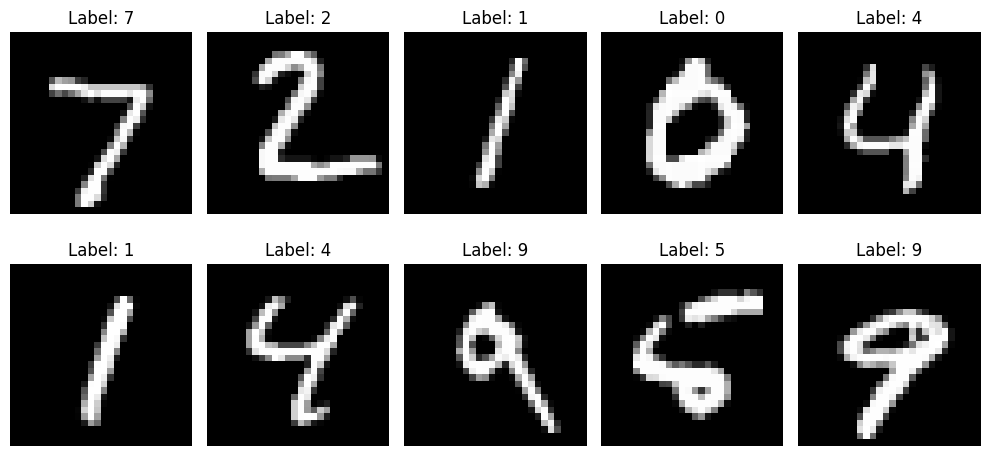

In [ ]:
# Display images and corresponding labels
images, labels = next(iter(test_dataloader))

fig, axs = plt.subplots(2, 5, figsize=(10, 5))

print(f"axs = {axs}")
print(f"axs.flat = {axs.flat}")

for i, ax in enumerate(axs.flat):
    ax.imshow(images[i].squeeze(), cmap="gray") # torch.squeeze() removes dimensions of size 1 from a tensor
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Build NN
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28*28, 250)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(250, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x


In [ ]:
# Initiate the NN
model = NeuralNetwork().to(device)

print(model)

NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=250, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=250, out_features=10, bias=True)
)


In [ ]:
# Loss Function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
# Train the NN
num_epochs = 15

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0

    for images, labels in train_dataloader:
        images = images.to(device)
        labels = labels.to(device)

        # Reset optimizer
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropogation
        loss.backward()

        # Update weights
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_dataloader)

    print("---")
    print(f"Epoch # {epoch}/{num_epochs}")
    print(f"Loss = {epoch_loss:.4f}")
    print("---")

---
Epoch # 0/15
Loss = 0.2764
---
---
Epoch # 1/15
Loss = 0.1140
---
---
Epoch # 2/15
Loss = 0.0767
---
---
Epoch # 3/15
Loss = 0.0554
---
---
Epoch # 4/15
Loss = 0.0421
---
---
Epoch # 5/15
Loss = 0.0310
---
---
Epoch # 6/15
Loss = 0.0246
---
---
Epoch # 7/15
Loss = 0.0192
---
---
Epoch # 8/15
Loss = 0.0162
---
---
Epoch # 9/15
Loss = 0.0125
---
---
Epoch # 10/15
Loss = 0.0104
---
---
Epoch # 11/15
Loss = 0.0097
---
---
Epoch # 12/15
Loss = 0.0063
---
---
Epoch # 13/15
Loss = 0.0088
---
---
Epoch # 14/15
Loss = 0.0056
---


In [ ]:
# Test the NN
model.eval()

total_correct = 0
total_entries = 0

with torch.no_grad():
    for images, labes in test_dataloader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        # print(f"Size of ouputs = {outputs.shape}")
        # print(f"Size of ouputs[0] = {outputs[0].shape}")
        # print(f"outputs[0] = {outputs[0]}")
        # print(f"{torch.max(outputs, dim=1)}")

        values, predicted_values = torch.max(outputs, dim=1)
        # print(f"predicted_values = {predicted_values}")
        # print(f"labels = {labels}")

        num_entries = len(labels)
        # print(f"num_entries = {num_entries}")
        total_entries += num_entries

        num_correct = (predicted_values==labels).sum()
        # print(f"num_correct = {num_correct}")
        total_correct += num_correct

print(f"total_entries = {total_entries}")
print(f"total_correct = {total_correct}")
print(f"accuracy = {(total_correct/total_entries)*100:.2f} %")


total_entries = 10000
total_correct = 1037
accuracy = 10.37 %


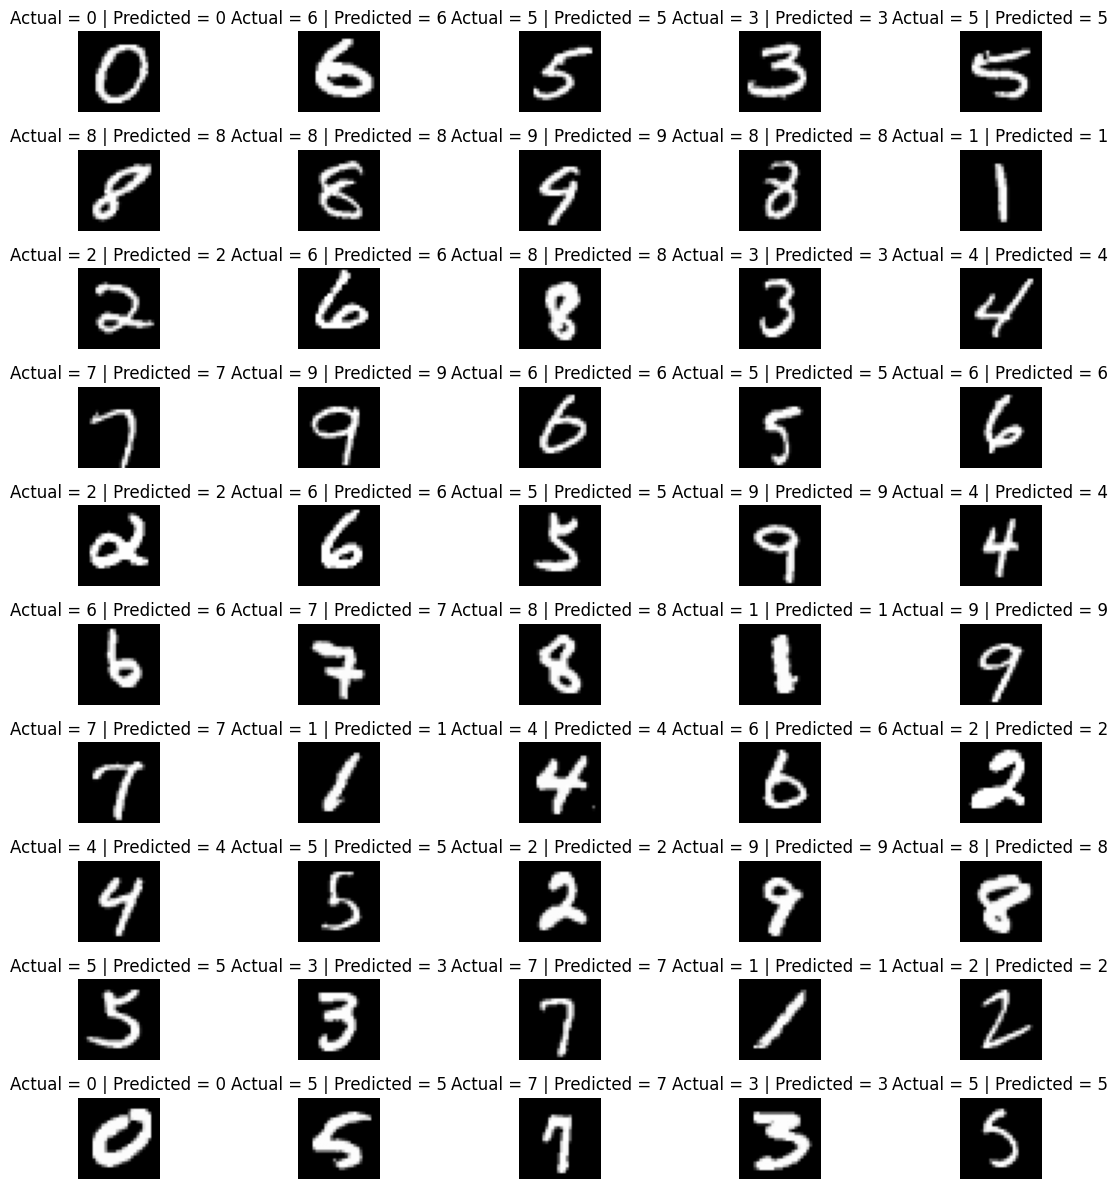

In [ ]:
model.eval()

images, labels = next(iter(test_dataloader))
images = images.to(device)
labels = labels.to(device)

with torch.no_grad():
    outputs = model(images)
    values, predicted_index = torch.max(outputs, dim=1)

images = images.cpu()
predicted_index = predicted_index.cpu()

fig, axs = plt.subplots(10, 5, figsize=(12, 12))

for i, ax in enumerate(axs.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Actual = {labels[i].item()} | Predicted = {predicted_index[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

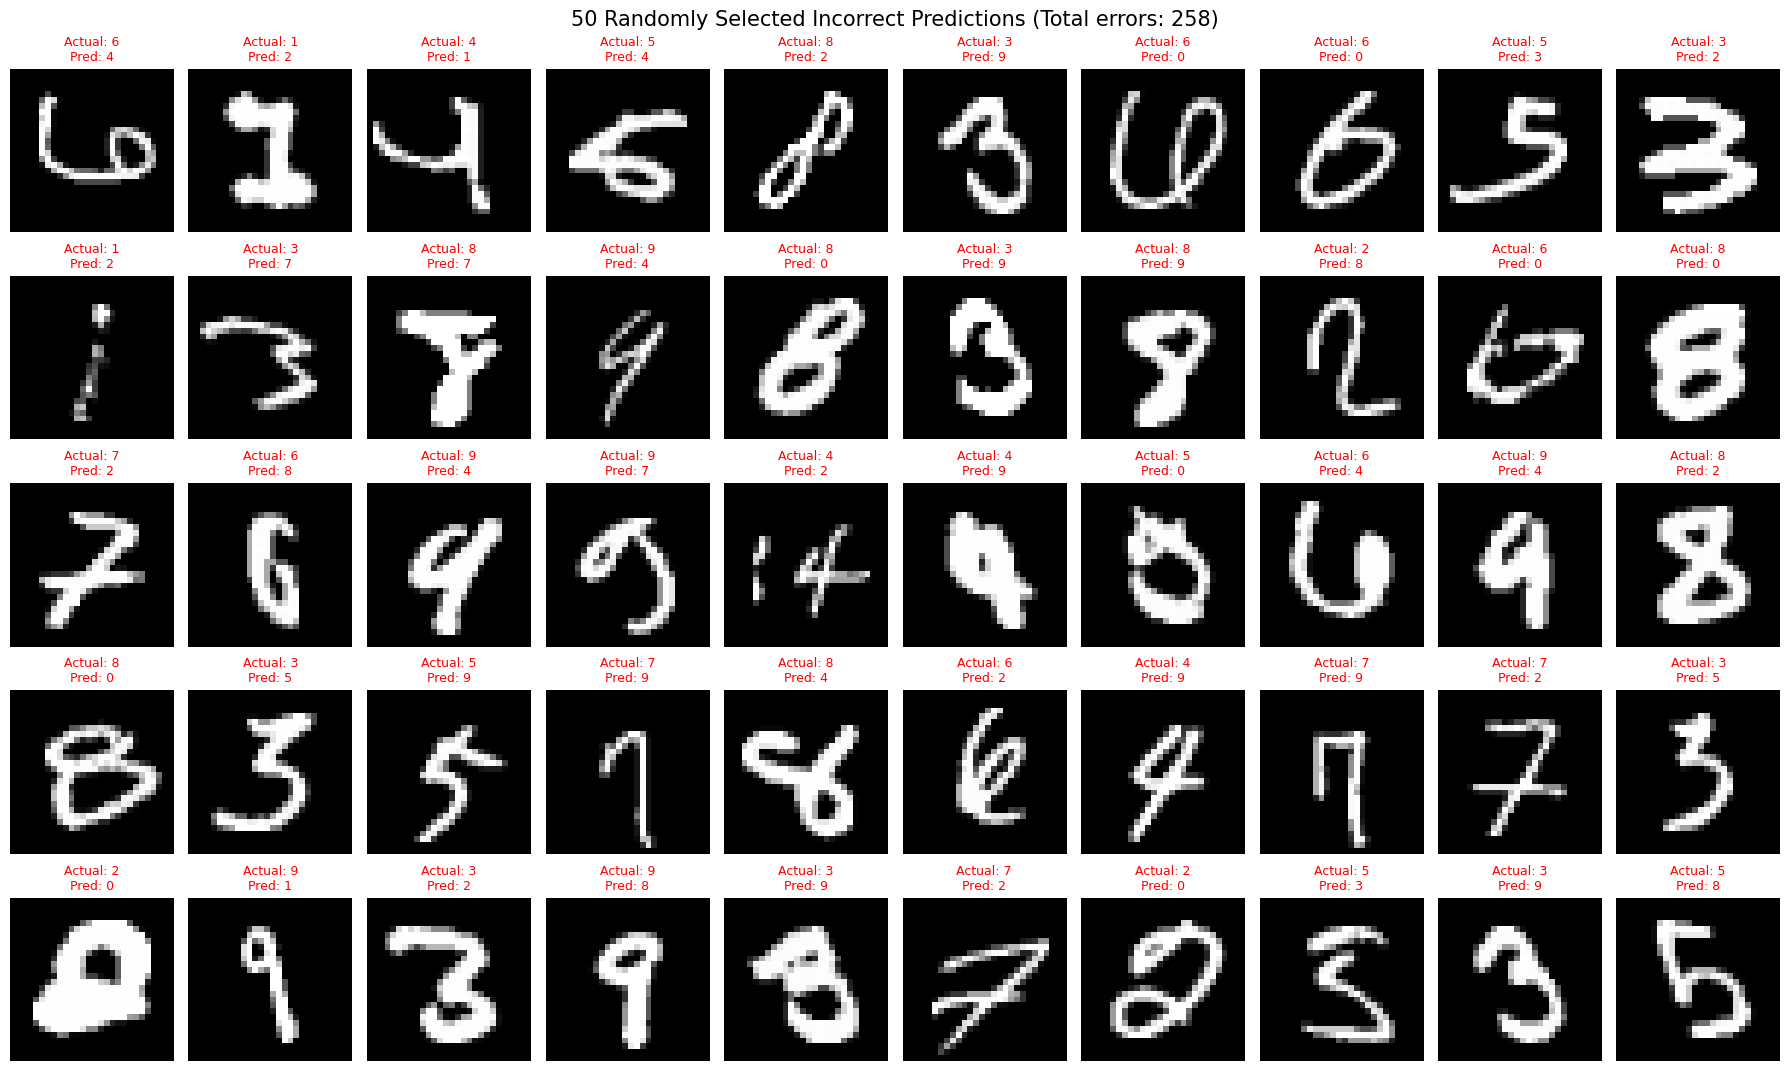

In [ ]:
## AI generated (human not verified code)

import torch
import matplotlib.pyplot as plt
import random

model.eval()

wrong_images = []
wrong_labels = []
wrong_predictions = []

# Collect all incorrect predictions
with torch.no_grad():

    for images, labels in test_dataloader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        # Find indices where prediction is incorrect
        incorrect_indices = (predicted != labels).nonzero(
            as_tuple=True
        )[0]

        for idx in incorrect_indices:

            wrong_images.append(images[idx].cpu())
            wrong_labels.append(labels[idx].item())
            wrong_predictions.append(predicted[idx].item())


# Randomly select 50 incorrect predictions
num_samples = min(50, len(wrong_images))

random_indices = random.sample(
    range(len(wrong_images)),
    num_samples
)


# Visualize
fig, axes = plt.subplots(5, 10, figsize=(18, 11))

for i, ax in enumerate(axes.flat):

    if i < num_samples:

        idx = random_indices[i]

        ax.imshow(
            wrong_images[idx].squeeze(),
            cmap="gray"
        )

        actual = wrong_labels[idx]
        predicted = wrong_predictions[idx]

        ax.set_title(
            f"Actual: {actual}\nPred: {predicted}",
            fontsize=9,
            color="red"
        )

    ax.axis("off")


plt.suptitle(
    f"50 Randomly Selected Incorrect Predictions (Total errors: {len(wrong_images)})",
    fontsize=15
)

plt.tight_layout()
plt.show()
